## COU 07506 — DIGITAL SIGNAL PROCESSING

## WEEK 1 — LAB 0: Setting Up the DSP Laboratory

**Name:** DANIEL MICHAEL MWAMAGE

**Registration Number:** 240242439891

**Date:** 23 November 2026

**Group:** GROUP 12

## Task 1.1 — Your First Notebook

In [1]:
print("COU07506 - Digital Signal Processing")
print("My first laboratory notebook")
print("Python is working correctly!")

COU07506 - Digital Signal Processing
My first laboratory notebook
Python is working correctly!


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

In [6]:
n = np.arange(-5, 11)

delta = (n == 0).astype(float)          # unit impulse
step = (n >= 0).astype(float)           # unit step
ramp = n * step                         # unit ramp
expo = 0.8**n * step                    # real exponential

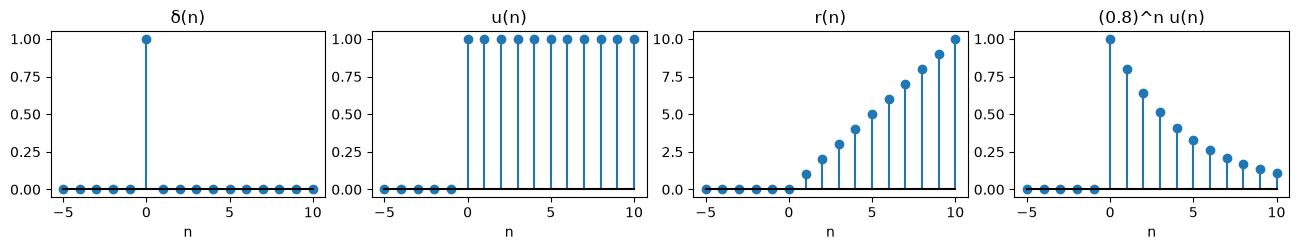

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()

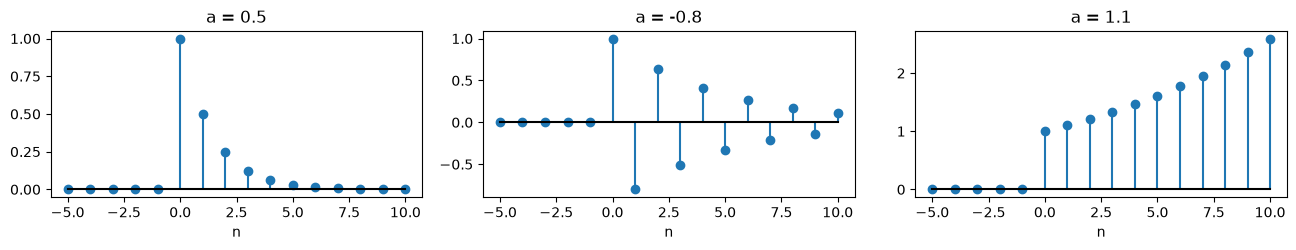

In [8]:
a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 2.6))

for ax, a in zip(axes, a_values):
    x = a**n * (n >= 0)
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()

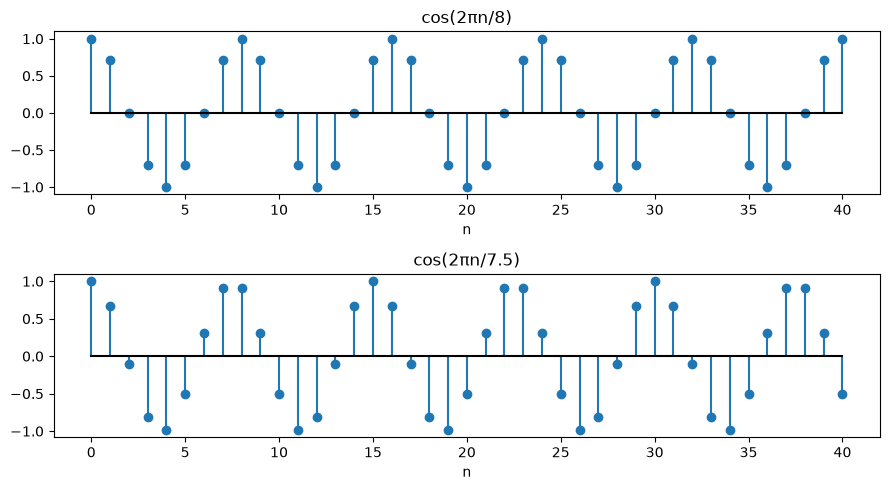

In [9]:
n = np.arange(0, 41)

x1 = np.cos(2*np.pi*n/8)
x2 = np.cos(2*np.pi*n/7.5)

fig, axes = plt.subplots(2, 1, figsize=(9, 5))

axes[0].stem(n, x1, basefmt="k-")
axes[0].set_title("cos(2πn/8)")
axes[0].set_xlabel("n")

axes[1].stem(n, x2, basefmt="k-")
axes[1].set_title("cos(2πn/7.5)")
axes[1].set_xlabel("n")

plt.tight_layout()
plt.show()

### Task 1.2 – Observations

1. For a = 0.5, the exponential signal decreases towards zero.
2. For a = -0.8, the signal alternates between positive and negative values.
3. For a = 1.1, the exponential signal increases as n increases.
4. The first cosine signal repeats every 8 samples.
5. The second cosine signal repeats every 15 samples.
6. Both cosine signals are periodic.

## Task 1.3 – Record and Plot a Real Audio Signal

fname = "my_voice.wav"

fs = 44100 Hz, duration = 5.50 s, samples = 242688


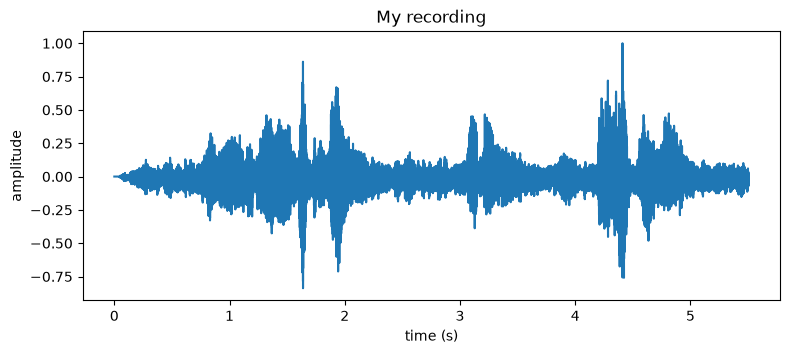

In [14]:
import os

fname = "my_voice.wav"                      # change to your file name
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:                          # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))               # normalise to [-1, 1]
else:                                       # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.show()

In [15]:
from IPython.display import Audio

Audio(x, rate=fs)